# Bagging Exercises

![Bagging.png](../asets/Bagging.png)

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга


## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

In [1]:
from __future__ import print_function
import os
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

from sklearnex import patch_sklearn
patch_sklearn()

%matplotlib inline
sns.set_style('whitegrid')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

In [2]:
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)
data.head()

(5000, 21)


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

In [3]:
print('уникальных телефонов:', data.phone_number.nunique(), 'из', len(data))
print('штатов:', data.state.nunique(), ' кодов города:', data.area_code.unique())
data.drop(['state', 'area_code', 'phone_number'], axis=1, inplace=True)
data.columns

уникальных телефонов: 5000 из 5000
штатов: 51  кодов города: [415 408 510]


Index(['account_length', 'intl_plan', 'voice_mail_plan',
       'number_vmail_messages', 'total_day_minutes', 'total_day_calls',
       'total_day_charge', 'total_eve_minutes', 'total_eve_calls',
       'total_eve_charge', 'total_night_minutes', 'total_night_calls',
       'total_night_charge', 'total_intl_minutes', 'total_intl_calls',
       'total_intl_charge', 'number_customer_service_calls', 'churned'],
      dtype='str')

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

In [4]:
data.dtypes

account_length                     int64
intl_plan                            str
voice_mail_plan                      str
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

In [5]:
# yes/no -> 1/0, целевая переменная bool -> 0/1
for col in ['intl_plan', 'voice_mail_plan']:
    data[col] = (data[col] == 'yes').astype(int)
data['churned'] = data['churned'].astype(int)
data.dtypes.value_counts().to_dict(), data[['intl_plan', 'voice_mail_plan', 'churned']].mean().round(3).to_dict()

({dtype('int64'): 10, dtype('float64'): 8},
 {'intl_plan': 0.095, 'voice_mail_plan': 0.265, 'churned': 0.141})

**Ответ.**

В данных 5000 клиентов и 21 столбец. Удалены `phone_number`, `state` и `area_code`. Номер телефона у каждого клиента свой, это просто идентификатор, для прогноза он бесполезен. Штатов 51, и вряд ли штат сам по себе влияет на отток, а при one-hot кодировании получилось бы еще 50 столбцов. Кодов города всего 3, и это скорее метка, чем число.

`intl_plan` и `voice_mail_plan` переведены из yes/no в 1/0, `churned` из bool в 0/1. Теперь все признаки числовые.

## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

In [6]:
data.churned.value_counts(), data.churned.value_counts(normalize=True).round(4)

(churned
 0    4293
 1     707
 Name: count, dtype: int64,
 churned
 0    0.8586
 1    0.1414
 Name: proportion, dtype: float64)

Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

In [7]:
feature_cols = data.columns[:-1]

# Get the split indexes
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=1500, random_state=42)
train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data.churned))

# Create the dataframes
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'churned']

X_test  = data.loc[test_idx, feature_cols]
y_test  = data.loc[test_idx, 'churned']

print('train:', len(y_train), ' test:', len(y_test))
pd.DataFrame({'train': y_train.value_counts(normalize=True), 'test': y_test.value_counts(normalize=True)}).round(4)

train: 3500  test: 1500


,train,test
churned,,
0,0.8586,0.8587
1,0.1414,0.1413


**Ответ.**

Ушли 707 клиентов из 5000, это около 14%, то есть классы несбалансированы. Поэтому разбиение стратифицировано по `churned` (1500 клиентов в test). Доля ушедших в train и test получилась одинаковой, 14.1%.

## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.

In [8]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [9]:
# Initialize the random forest estimator
# Note that the number of trees is not setup here
RF = RandomForestClassifier(oob_score=True,
                            random_state=42,
                            warm_start=True,
                            n_jobs=-1)

oob_list = list()

# Iterate through all of the possibilities for number of trees
for n_trees in [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]:

    # Use this to set the number of trees
    RF.set_params(n_estimators=n_trees)

    # Fit the model
    RF.fit(X_train, y_train)

    # Get the oob error
    oob_error = 1 - RF.oob_score_

    # Store it
    oob_list.append(pd.Series({'n_trees': n_trees, 'oob': oob_error}))

rf_oob_df = pd.concat(oob_list, axis=1).T.set_index('n_trees')
print('деревьев в модели:', len(RF.estimators_))
rf_oob_df.T.round(4)

деревьев в модели: 400


n_trees,15.0,20.0,30.0,40.0,50.0,100.0,150.0,200.0,300.0,400.0
oob,0.0597,0.0534,0.0497,0.0474,0.0491,0.0451,0.0451,0.0449,0.0443,0.044


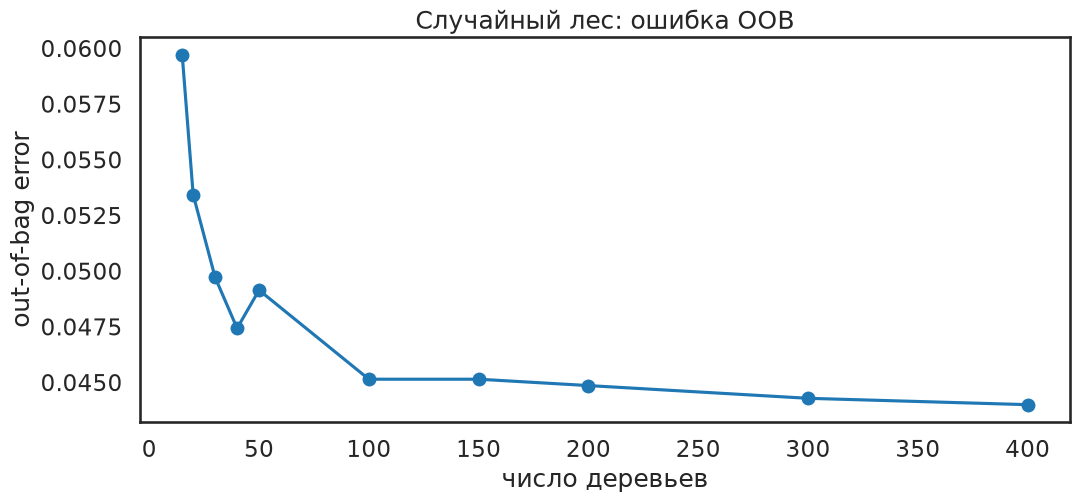

In [10]:
sns.set_context('talk')
sns.set_style('white')

ax = rf_oob_df.plot(legend=False, marker='o', figsize=(12, 5))
ax.set(ylabel='out-of-bag error', xlabel='число деревьев', title='Случайный лес: ошибка OOB');

Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

**Ответ.**

OOB-ошибка быстро падает до 100 деревьев (с 0.060 при 15 деревьях до 0.045), а дальше почти не меняется, при 400 деревьях 0.044. На 50 деревьях есть небольшой скачок вверх, но это скорее случайность. То есть примерно после 100-150 деревьев добавлять новые уже почти не имеет смысла.

OOB-ошибка считается на объектах, которые не попали в бутстреп-выборку конкретного дерева (это примерно треть данных), поэтому отдельная валидационная выборка не нужна.

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.

In [11]:
# Initialize the extra trees estimator: bootstrap=True нужен, иначе нет out-of-bag объектов
EF = ExtraTreesClassifier(oob_score=True,
                          random_state=42,
                          warm_start=True,
                          bootstrap=True,
                          n_jobs=-1)

oob_list = list()

# Iterate through all of the possibilities for number of trees
for n_trees in [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]:

    # Use this to set the number of trees
    EF.set_params(n_estimators=n_trees)
    EF.fit(X_train, y_train)

    # oob error
    oob_error = 1 - EF.oob_score_
    oob_list.append(pd.Series({'n_trees': n_trees, 'oob': oob_error}))

et_oob_df = pd.concat(oob_list, axis=1).T.set_index('n_trees')

et_oob_df.T.round(4)

n_trees,15.0,20.0,30.0,40.0,50.0,100.0,150.0,200.0,300.0,400.0
oob,0.0809,0.072,0.0694,0.0643,0.0674,0.0629,0.0611,0.0626,0.0603,0.0609


Объедините два датафрейма в один, чтобы упростить построение графиков.

In [12]:
oob_df = pd.concat([rf_oob_df.rename(columns={'oob':'RandomForest'}),
                    et_oob_df.rename(columns={'oob':'ExtraTrees'})], axis=1)

oob_df.round(4)

,RandomForest,ExtraTrees
n_trees,,
15.0,0.0597,0.0809
20.0,0.0534,0.0720
30.0,0.0497,0.0694
40.0,0.0474,0.0643
50.0,0.0491,0.0674
100.0,0.0451,0.0629
150.0,0.0451,0.0611
200.0,0.0449,0.0626
300.0,0.0443,0.0603


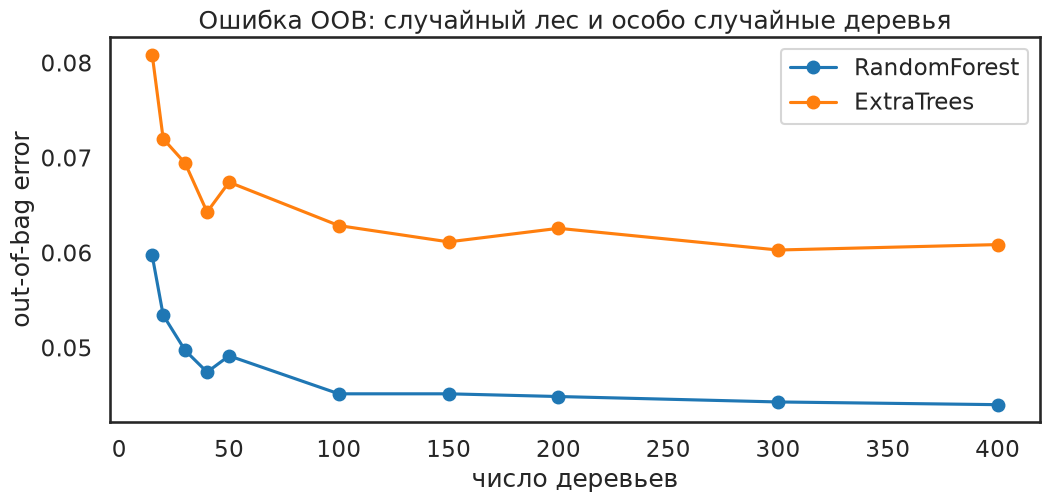

In [13]:
sns.set_context('talk')
sns.set_style('white')

ax = oob_df.plot(marker='o', figsize=(12, 5))
ax.set(ylabel='out-of-bag error', xlabel='число деревьев', title='Ошибка OOB: случайный лес и особо случайные деревья');

Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

**Ответ.**

У ExtraTrees OOB-ошибка выше при любом числе деревьев: при 400 деревьях 0.061 против 0.044 у случайного леса. Кривые идут почти параллельно.

ExtraTrees выбирает порог разбиения случайно, а не лучший, поэтому каждое дерево получается слабее. Здесь, видимо, важны точные пороги (например, по числу звонков в поддержку), и случайный лес находит их лучше. Еще с `bootstrap=True` каждое дерево ExtraTrees видит только часть данных (по умолчанию оно обучается на всех), это тоже его ослабляет.

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?

In [14]:
# Random forest with 400 estimators
model = RF.set_params(n_estimators=400)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [15]:
cr = classification_report(y_test, y_pred, digits=4)
print(cr)

              precision    recall  f1-score   support

           0     0.9631    0.9930    0.9778      1288
           1     0.9477    0.7689    0.8490       212

    accuracy                         0.9613      1500
   macro avg     0.9554    0.8809    0.9134      1500
weighted avg     0.9609    0.9613    0.9596      1500



In [16]:
score_df = pd.DataFrame({'accuracy': accuracy_score(y_test, y_pred),
                         'precision': precision_score(y_test, y_pred),
                         'recall': recall_score(y_test, y_pred),
                         'f1': f1_score(y_test, y_pred),
                         'auc': roc_auc_score(y_test, y_prob),
                         'average precision': average_precision_score(y_test, y_prob)},
                         index=pd.Index([0]))
print(f'accuracy константы "никто не уйдет": {1 - y_test.mean():.4f}')
score_df.round(4)

accuracy константы "никто не уйдет": 0.8587


,accuracy,precision,recall,f1,auc,average precision
0,0.9613,0.9477,0.7689,0.849,0.9232,0.888


Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

**Ответ.**

Беру случайный лес из 400 деревьев. На test: accuracy 0.961, precision 0.948, recall 0.769, F1 0.849, AUC 0.923.

Больше всего может ввести в заблуждение accuracy. Если всегда говорить "клиент не уйдет", accuracy уже будет 0.859, хотя ни один уходящий клиент не найден. Поэтому 0.961 не так впечатляет, как кажется.

Самый важный показатель, по-моему, recall для ушедших клиентов, то есть сколько из них модель находит (здесь 77%), ведь их нужно успеть удержать. Но смотреть его надо вместе с precision, чтобы не было слишком много ложных тревог, поэтому удобно смотреть и на F1.

## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.

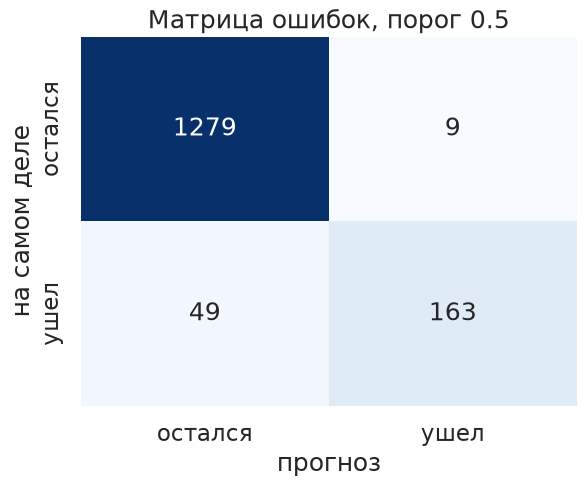

In [17]:
sns.set_context('talk')
cm = confusion_matrix(y_test, y_pred)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                 xticklabels=['остался', 'ушел'], yticklabels=['остался', 'ушел'])
ax.set(xlabel='прогноз', ylabel='на самом деле', title='Матрица ошибок, порог 0.5');

Кривые ROC-AUC и «точность-охватываемость».

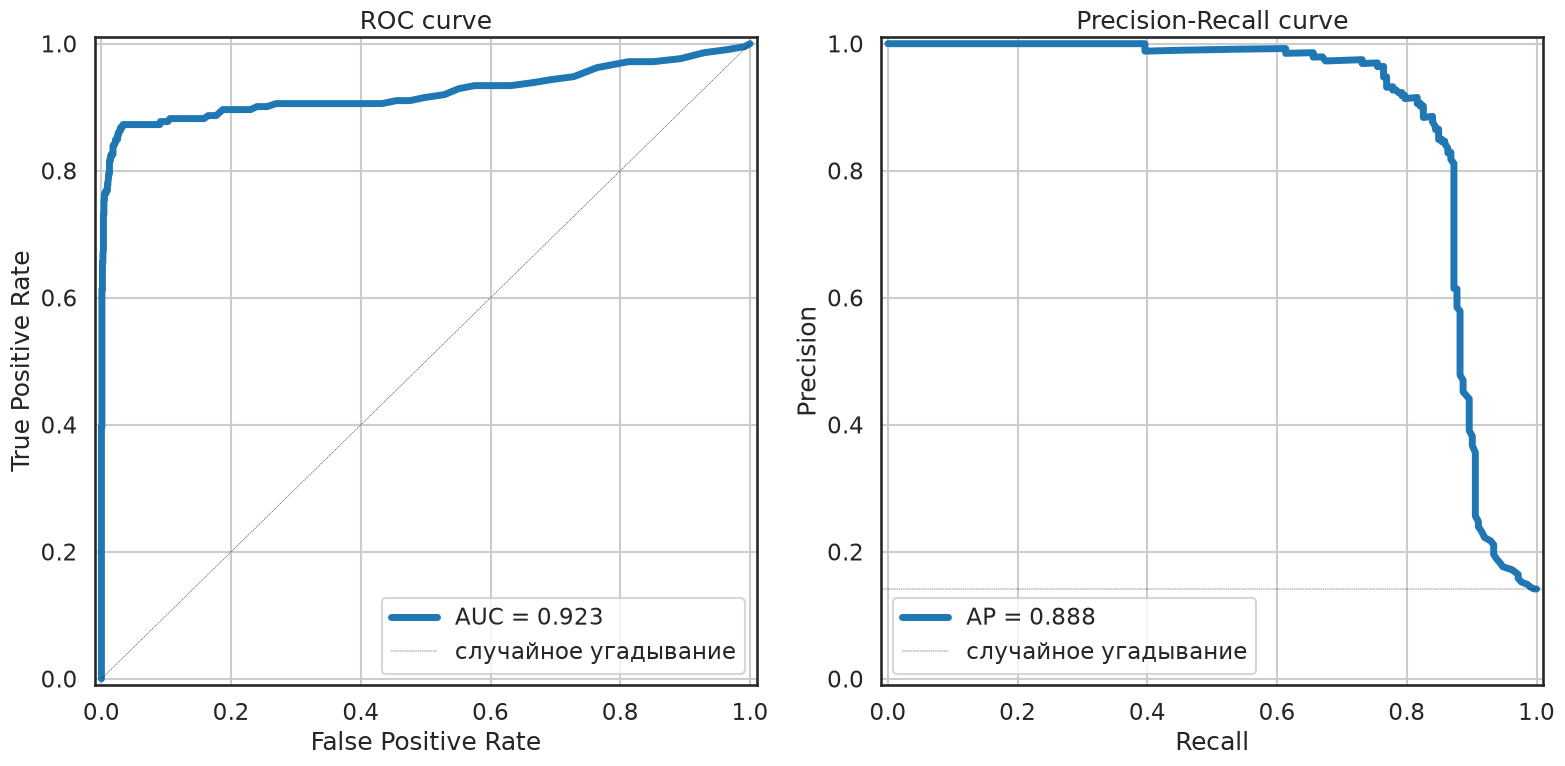

In [18]:
sns.set_context('talk')

fig, axList = plt.subplots(ncols=2)
fig.set_size_inches(16, 8)

# Get the probabilities for each of the two categories
y_prob = model.predict_proba(X_test)

# Plot the ROC-AUC curve
ax = axList[0]

fpr, tpr, thresholds = roc_curve(y_test, y_prob[:,1])
ax.plot(fpr, tpr, linewidth=5, label=f'AUC = {roc_auc_score(y_test, y_prob[:, 1]):.3f}')
# It is customary to draw a diagonal dotted line in ROC plots.
# This is to indicate completely random prediction. Deviation from this
# dotted line towards the upper left corner signifies the power of the model.
ax.plot([0, 1], [0, 1], ls='--', color='black', lw=.3, label='случайное угадывание')
ax.set(xlabel='False Positive Rate',
       ylabel='True Positive Rate',
       xlim=[-.01, 1.01], ylim=[-.01, 1.01],
       title='ROC curve')
ax.legend(loc='lower right')
ax.grid(True)

# Plot the precision-recall curve
ax = axList[1]

precision, recall, _ = precision_recall_curve(y_test, y_prob[:,1])
ax.plot(recall, precision, linewidth=5, label=f'AP = {average_precision_score(y_test, y_prob[:, 1]):.3f}')
ax.axhline(y_test.mean(), ls='--', color='black', lw=.3, label='случайное угадывание')
ax.set(xlabel='Recall', ylabel='Precision',
       xlim=[-.01, 1.01], ylim=[-.01, 1.01],
       title='Precision-Recall curve')
ax.legend(loc='lower left')
ax.grid(True)

plt.tight_layout()

Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.

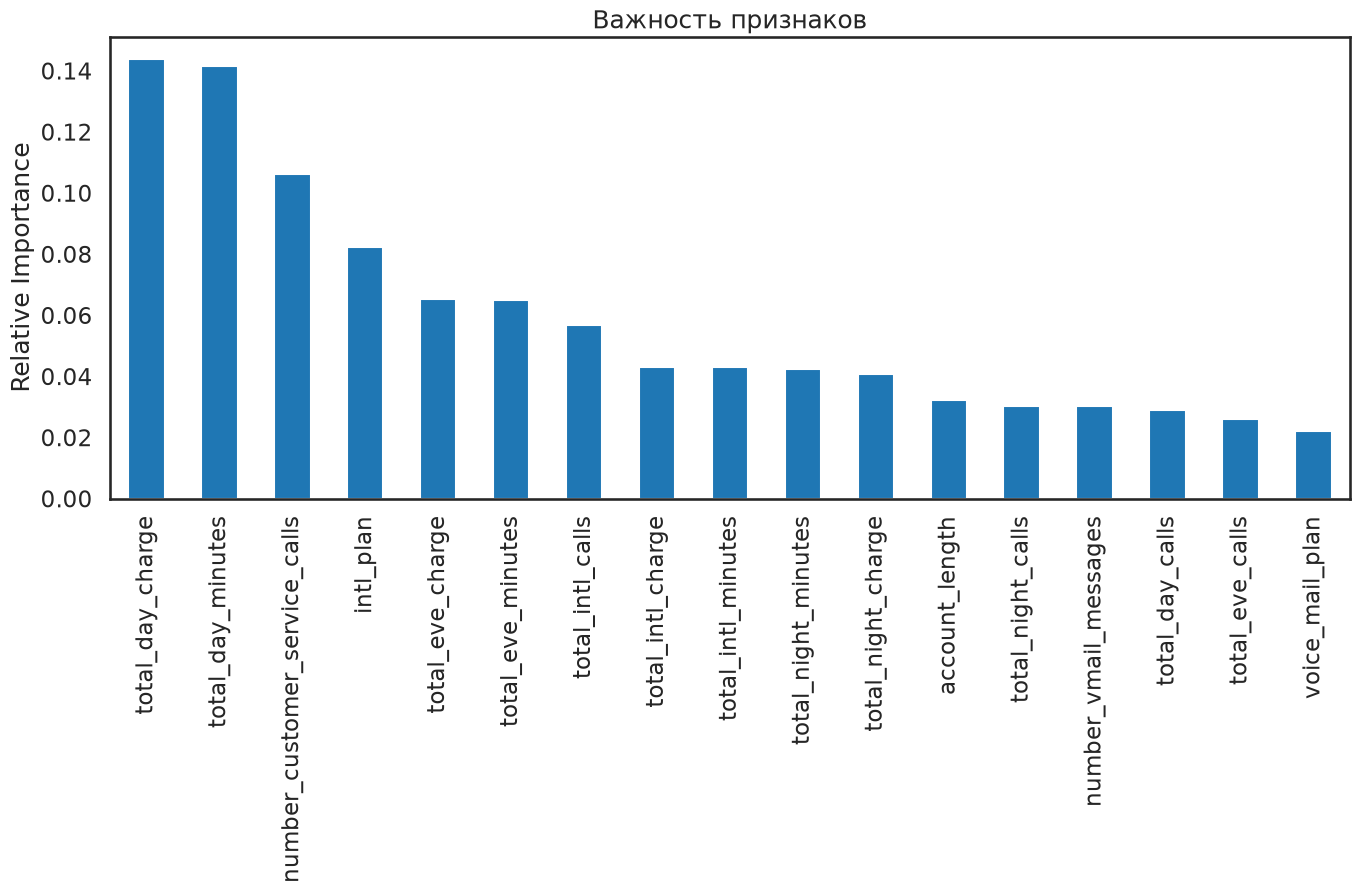

total_day_charge                 0.1440
total_day_minutes                0.1415
number_customer_service_calls    0.1063
intl_plan                        0.0825
total_eve_charge                 0.0653
total_eve_minutes                0.0650
total_intl_calls                 0.0570
total_intl_charge                0.0432
total_intl_minutes               0.0430
total_night_minutes              0.0423
total_night_charge               0.0408
account_length                   0.0321
total_night_calls                0.0302
number_vmail_messages            0.0302
total_day_calls                  0.0289
total_eve_calls                  0.0260
voice_mail_plan                  0.0220
dtype: float64

In [19]:
feature_imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)

ax = feature_imp.plot(kind='bar', figsize=(16, 6))
ax.set(ylabel='Relative Importance', title='Важность признаков');
plt.show()
feature_imp.round(4)

In [20]:
# total_day_charge и total_day_minutes почти одно и то же
print('корреляция:', data['total_day_minutes'].corr(data['total_day_charge']))
# доля ушедших в зависимости от числа звонков в поддержку
data.groupby('number_customer_service_calls').churned.mean().round(3)

корреляция: 0.9999999509831994


number_customer_service_calls
0    0.118
1    0.106
2    0.108
3    0.110
4    0.440
5    0.604
6    0.647
7    0.538
8    0.500
9    1.000
Name: churned, dtype: float64

**Ответ.**

По матрице ошибок: из 1288 оставшихся клиентов неправильно предсказаны 9, а из 212 ушедших модель нашла 163 и пропустила 49.

ROC-кривая сначала резко поднимается (TPR около 0.87 уже при FPR 0.03), а потом идет почти горизонтально, AUC = 0.923. Precision на кривой precision-recall держится выше 0.95 примерно до recall 0.75, а после 0.87 резко падает (AP = 0.888). То есть большую часть уходящих модель находит уверенно, а остальных найти можно только ценой большого числа ложных тревог.

Самые важные признаки - `total_day_charge` и `total_day_minutes`, дальше `number_customer_service_calls` и `intl_plan`. `total_day_charge` и `total_day_minutes` по сути один и тот же признак (корреляция почти 1, плата просто пропорциональна минутам), поэтому важность делится между ними. По звонкам в поддержку виден резкий скачок: при 0-3 звонках уходят около 11% клиентов, а при 4 звонках уже 44%.